<center><font size=7>Automobile Data Analysis and Mileage Prediction Using Machine Learning</font></center>

## 1.INFRODUCTION :

- The Automobile Mileage Prediction project is a Machine Learning project developed using Python. The main objective of this project is to analyze automobile data and predict the mileage of vehicles based on different features.

-  In this project, the Automobile dataset is used to understand the relationship between vehicle characteristics such as cylinders, displacement, horsepower, weight, acceleration, and model year with vehicle mileage.

- The project uses data preprocessing techniques to clean the dataset and remove missing and duplicate values. Data visualization techniques are used to understand the relationship between different attributes.

- Linear Regression, a supervised machine learning algorithm, is used to build three different prediction models. The performance of these models is evaluated using Mean Squared Error (MSE) and R-squared (R²) score.

- The project helps to identify which vehicle features contribute to mileage prediction and compare the performance of different machine learning models.

## 2.Objectives

 - To understand and analyze automobile data.

 - To perform data cleaning and preprocessing.

 - To visualize relationships between automobile features.

 - To develop mileage prediction models using Linear Regression.

 - To compare three different machine learning models.

 - To evaluate model performance using MSE and R² score.

## 3. Dataset Description

#### The Automobile dataset contains information about different vehicles and their technical specifications. ####

In [1]:
# For reading and manipulating data
import pandas as pd

# For numerical operations
import numpy as np

# For data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import Linear Regression model
from sklearn.linear_model import LinearRegression

# Utilities for performance evaluation
from sklearn.metrics import mean_squared_error, r2_score

# Utilities for data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Load Data
 

#####           The read_csv() function is used to load the CSV dataset into a Pandas DataFrame.The data download in kaggle website.

In [2]:
mpg_data = pd.read_csv(r"C:\Users\acer\Desktop\machine_learning\data\Automobile.csv")

In [3]:
mpg_data.head(5)

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


## 4. Data Overview

##### info() function display information about the data

In [4]:
mpg_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          398 non-null    str    
 1   mpg           398 non-null    float64
 2   cylinders     398 non-null    int64  
 3   displacement  398 non-null    float64
 4   horsepower    392 non-null    float64
 5   weight        398 non-null    int64  
 6   acceleration  398 non-null    float64
 7   model_year    398 non-null    int64  
 8   origin        398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


#####         Describe() function display a statisical summary of all numarical columns

In [5]:
mpg_data.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0


#### Show how many row and columns in dataset

In [6]:
mpg_data.shape

(398, 9)

#### Show all columns names in dataset

In [7]:
mpg_data.columns

Index(['name', 'mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin'],
      dtype='str')

In [8]:
mpg_data.isna().sum()

name            0
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [9]:
mpg_data=mpg_data.dropna()

#### Duplicate records are identified and removed to improve data quality and avoid biased predictions

In [10]:
mpg_data=mpg_data.drop_duplicates()

In [11]:
mpg_data.shape

(392, 9)

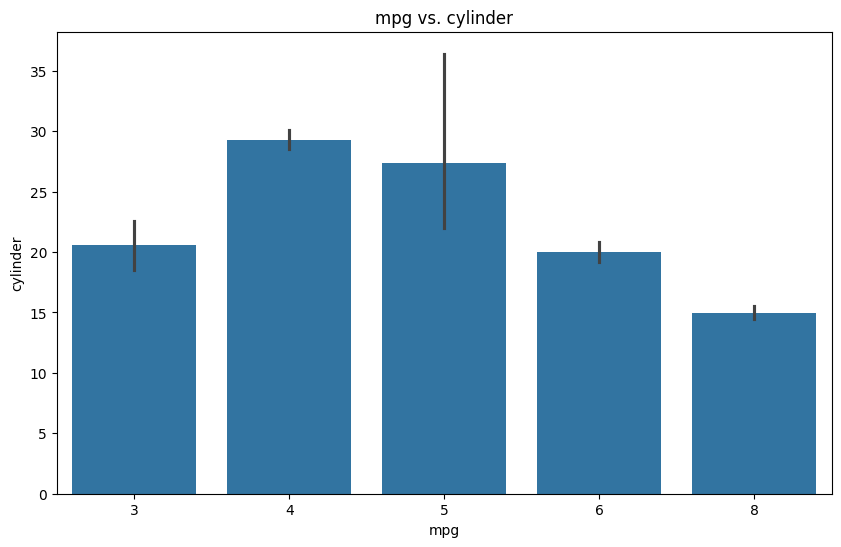

In [12]:
plt.figure(figsize=(10, 6))
sns.barplot(x='cylinders', y='mpg', data=mpg_data)
plt.title('mpg vs. cylinder')
plt.xlabel('mpg')
plt.ylabel('cylinder')
plt.show()

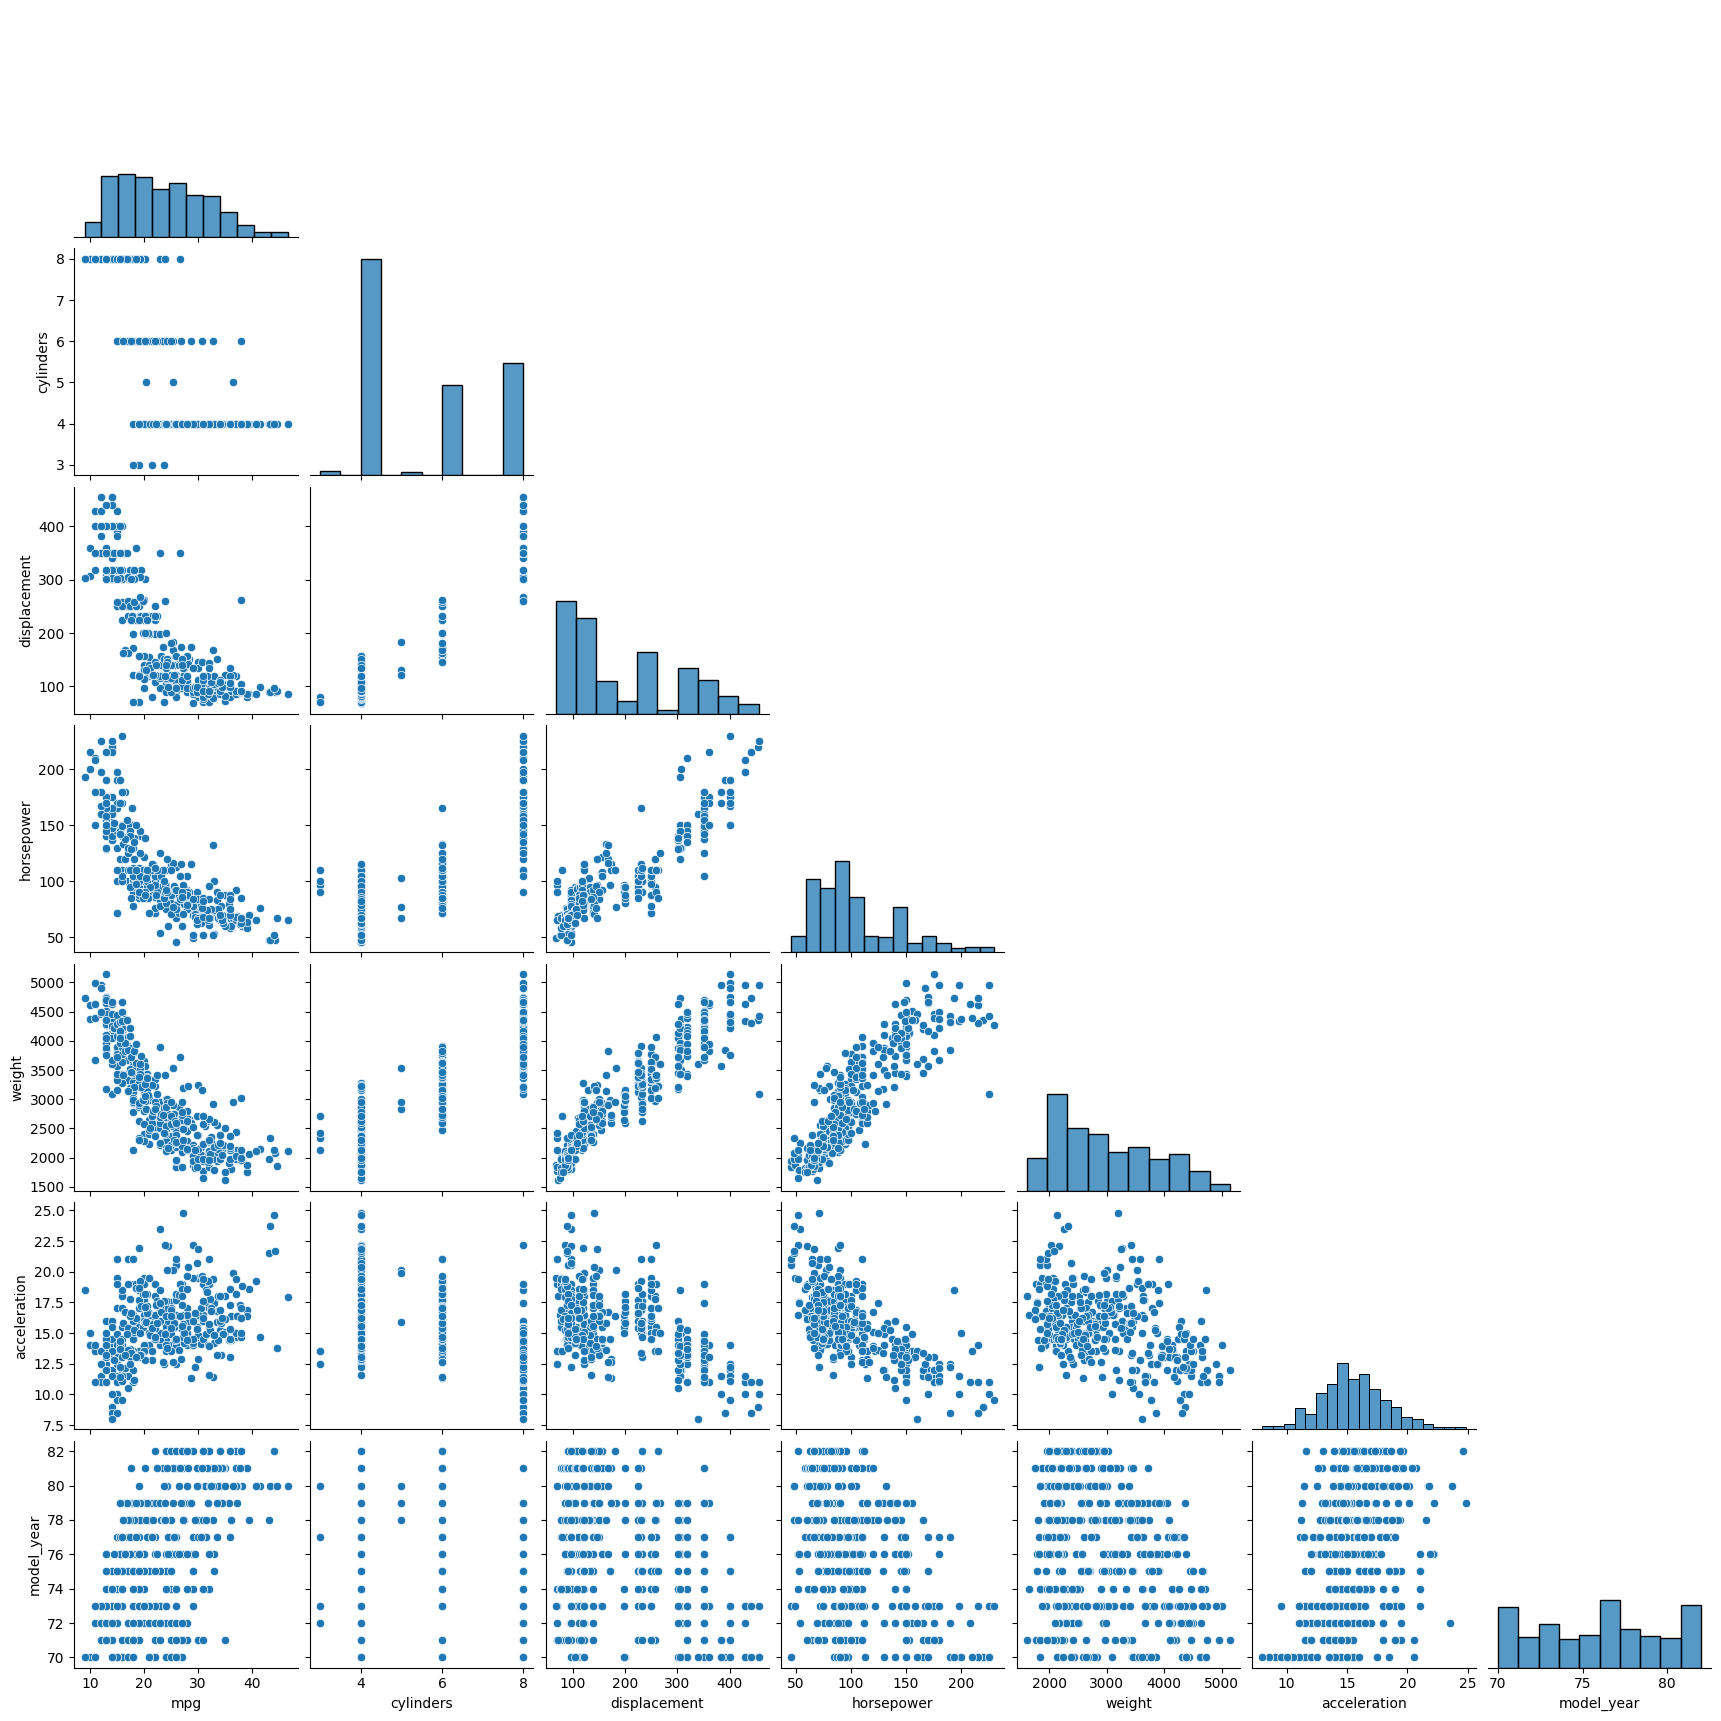

In [13]:
sns.pairplot(
    mpg_data,
    diag_kind="hist",
    corner=True
)

In [14]:
mpg_data=mpg_data.drop(columns=['name','origin'])

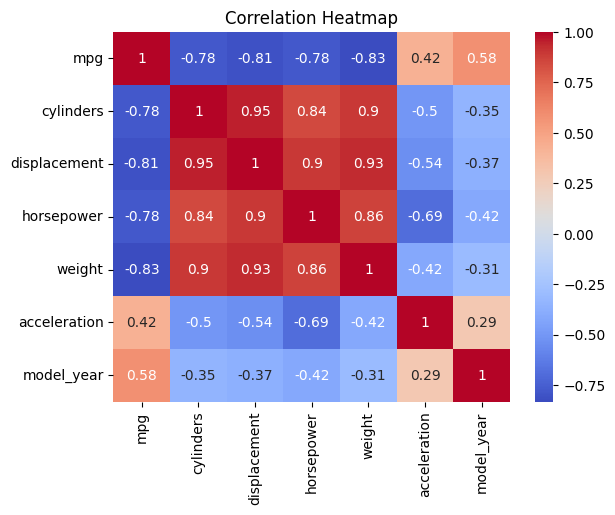

In [15]:
plt.Figure(figsize=(12,8))
sns.heatmap(mpg_data.corr(), annot= True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Spliting the data

The dataset is divided into input features (X) and the target variable (y) for model training and prediction.

The training data is used to train the machine learning model, while the testing data is used to evaluate how well the model performs on unseen data

In [16]:
x=mpg_data.drop('mpg',axis=1)
y=mpg_data['mpg']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

# **Model** **1**

## Acceleration-Based Prediction Model

### It shows that Automobile Mileage charges generally increase with Acceleration. However, since the R² value is low and the prediction error is high,Acceleration alone is not a strong predictor of Automobile Mileage charges.

In [18]:
model1_train  =X_train[['acceleration']]
model1_test = X_test[['acceleration']]

In [19]:
model1 = LinearRegression()
model1.fit(model1_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.24]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['acceleration']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.391
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [20]:
model1_train_predict = model1.predict(model1_train)
model1_test_predict = model1.predict(model1_test)

In [21]:
## check mean square error for the model

mes_model1_train = mean_squared_error(y_train,model1_train_predict)
r2_model1_train = r2_score(y_train,model1_train_predict)

In [22]:
mes_model1_test = mean_squared_error(y_test,model1_test_predict)
r2_model1_test = r2_score(y_test,model1_test_predict)

In [23]:
model_eval_results = pd.DataFrame(columns=['Model', 'Train_MSE', 'Train_R2', 'Test_MSE', 'Test_R2'])

In [24]:
model_eval_results.loc[len(model_eval_results)] = ['Model 1 (acceleration Only)', mes_model1_train,r2_model1_train , mes_model1_test,r2_model1_test ]

In [25]:
model_eval_results

,Model,Train_MSE,Train_R2,Test_MSE,Test_R2
0,Model 1 (acceleration Only),51.513673,0.19541,46.264559,0.125514


# **Model** **2**

## Acceleration & model_year Prediction Model

## Model 2 performs better than Model 1 because it uses both Acceleration and model_year as predictors. The lower MSE and higher R² values indicate improved prediction accuracy.

In [26]:
model2_train  =X_train[['model_year','acceleration']]
model2_test = X_test[['model_year','acceleration']]

In [27]:
model2 = LinearRegression()
model2.fit(model2_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[1.08,0.81]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['model_year','acceleration']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-71.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [28]:
model2_train_predict = model2.predict(model2_train)
model2_test_predict = model2.predict(model2_test)

In [29]:
## check mean square error for the model

mes_model2_train = mean_squared_error(y_train,model2_train_predict)
r2_model2_train = r2_score(y_train,model2_train_predict)

In [30]:
mes_model2_test = mean_squared_error(y_test,model2_test_predict)
r2_model2_test = r2_score(y_test,model2_test_predict)

In [31]:
model_eval_results.loc[len(model_eval_results)] = ['Model 2 (acceleration + model_year)', mes_model2_train,r2_model2_train , mes_model2_test,r2_model2_test ]

In [32]:
model_eval_results

,Model,Train_MSE,Train_R2,Test_MSE,Test_R2
0,Model 1 (acceleration Only),51.513673,0.19541,46.264559,0.125514
1,Model 2 (acceleration + model_year),37.784876,0.40984,31.824331,0.398461


# **Model** **3**

#### All Features Prediction Model

In [33]:
model3 = LinearRegression()
model3.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-0.09, 0. ,-0.01,-0.01, 0.06, 0.73]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['cylinders','displacement','horsepower','weight','acceleration', 'model_year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-12.38
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [34]:
model3_train_predict = model3.predict(X_train)
model3_test_predict = model3.predict(X_test)

In [35]:
mes_model3_train = mean_squared_error(y_train,model3_train_predict)
r2_model3_train = r2_score(y_train,model3_train_predict)

In [36]:
mes_model3_test = mean_squared_error(y_test,model3_test_predict)
r2_model3_test = r2_score(y_test,model3_test_predict)

In [37]:
model_eval_results.loc[len(model_eval_results)] = ['Model 3 (all)', mes_model3_train,r2_model3_train , mes_model3_test,r2_model3_test ]

In [38]:
model_eval_results

,Model,Train_MSE,Train_R2,Test_MSE,Test_R2
0,Model 1 (acceleration Only),51.513673,0.195410,46.264559,0.125514
1,Model 2 (acceleration + model_year),37.784876,0.409840,31.824331,0.398461
2,Model 3 (all),12.420114,0.806011,10.175163,0.807670


In [39]:
model_eval_results.info()

<class 'pandas.DataFrame'>
Index: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Model      3 non-null      str    
 1   Train_MSE  3 non-null      float64
 2   Train_R2   3 non-null      float64
 3   Test_MSE   3 non-null      float64
 4   Test_R2    3 non-null      float64
dtypes: float64(4), str(1)
memory usage: 144.0 bytes


In [40]:
type(model_eval_results)

pandas.DataFrame

Text(0, 0.5, 'Test R² Score')

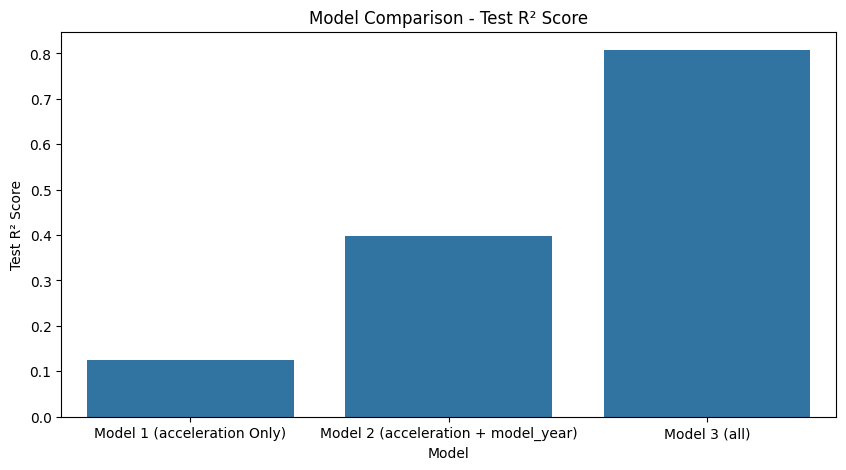

In [41]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=model_eval_results,
    x="Model",
    y="Test_R2"
)
plt.title("Model Comparison - Test R² Score")
plt.xlabel("Model")
plt.ylabel("Test R² Score")